# 12 · Membrane gas separation

A polymer film lets some gases through faster than others: hydrogen recovery, nitrogen from air, CO$_2$
from natural gas and biogas all run on the solution-diffusion mechanism with no phase change and no heat.
The design questions are the membrane's selectivity and permeance, the pressure ratio, the stage cut, and
how the flow pattern on the two sides changes the answer. This notebook computes permeate and retentate
compositions for the complete-mixing and cross-flow models, sizes the membrane area, and reads Robeson's
trade-off from the permeability table.

**What you will learn**
- read permeability tables and the selectivity trade-off
- compute permeate and retentate for complete mixing and cross flow
- size membrane area
- choose membranes for nitrogen generation and biogas upgrading

**Before you start:** notebook 02  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import datasets
from engsep import membranes as mb
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Permeabilities and the selectivity trade-off

               polymer    H2    O2     N2    CO2    CH4  O2/N2  CO2/CH4
           polysulfone   5.6   1.4   0.25   14.0   0.25   5.60    56.00
     cellulose acetate   2.6   0.8   0.20    6.0   0.20   4.00    30.00
  polyimide (Matrimid)  28.0   2.1   0.32   10.0   0.28   6.56    35.71
silicone rubber (PDMS) 650.0 600.0 280.00 3200.0 950.00   2.14     3.37
         polycarbonate  12.0   1.4   0.30    6.5   0.36   4.67    18.06
      polyethersulfone   7.8   0.6   0.11    3.4   0.10   5.45    34.00


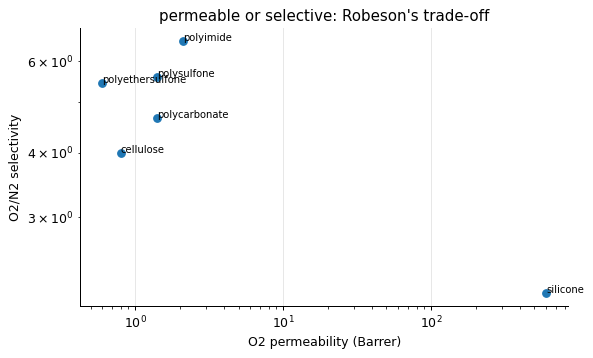

In [2]:
d = pd.read_csv(datasets.path("gas_permeabilities.csv"), comment="#")
d["O2/N2"] = d.O2 / d.N2
d["CO2/CH4"] = d.CO2 / d.CH4
print(d.round(2).to_string(index=False))
fig, ax = plt.subplots(); ax.loglog(d.O2, d["O2/N2"], "o")
for _, r in d.iterrows():
    ax.annotate(r.polymer.split(" ")[0], (r.O2, r["O2/N2"]), fontsize=8)
ax.set(xlabel="O2 permeability (Barrer)", ylabel="O2/N2 selectivity", title="permeable or selective: Robeson's trade-off"); plt.show()

The most permeable polymer (silicone rubber) is the least selective; the glassy polymers separate well but
slowly. Robeson's upper bound is the frontier of that trade-off, and every commercial membrane is a
compromise on it - thin skins (a fraction of a micron on a porous support) make the glassy polymers fast
enough to use.

## One membrane, complete mixing

In [3]:
alpha = 5.6                                                          # O2/N2 selectivity of polysulfone
x_f = 0.21
for r in (0.5, 0.2, 0.1, 0.05):
    row = [mb.complete_mixing(alpha, x_f, r, theta)["y_permeate"] for theta in (0.05, 0.2, 0.5)]
    print(f"pressure ratio p_perm/p_feed = {r:4.2f}: permeate O2 at stage cut 5 / 20 / 50 %: {row[0]:.3f} / {row[1]:.3f} / {row[2]:.3f}")

pressure ratio p_perm/p_feed = 0.50: permeate O2 at stage cut 5 / 20 / 50 %: 0.328 / 0.302 / 0.260
pressure ratio p_perm/p_feed = 0.20: permeate O2 at stage cut 5 / 20 / 50 %: 0.459 / 0.397 / 0.302
pressure ratio p_perm/p_feed = 0.10: permeate O2 at stage cut 5 / 20 / 50 %: 0.513 / 0.437 / 0.319
pressure ratio p_perm/p_feed = 0.05: permeate O2 at stage cut 5 / 20 / 50 %: 0.542 / 0.459 / 0.328


Two levers: a lower pressure ratio (higher feed pressure or vacuum on the permeate) raises the enrichment
towards the selectivity limit, and a lower stage cut keeps the permeate rich (the first permeate is the
purest; taking more dilutes it with what comes later). Air enriched to 35-45 % oxygen with a single membrane
is the usual outcome, which is exactly what medical oxygen concentrators and enriched-air combustion use.

## Cross flow versus complete mixing

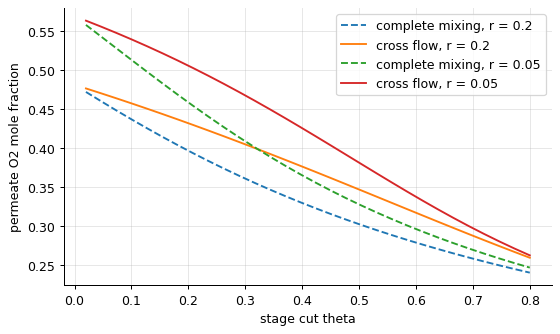

at r = 0.1 and theta = 0.3: complete mixing y = 0.392 (retentate 0.132); cross flow y = 0.446 (retentate 0.109)


In [4]:
thetas = np.linspace(0.02, 0.8, 30)
fig, ax = plt.subplots()
for r in (0.2, 0.05):
    ax.plot(thetas, [mb.complete_mixing(alpha, x_f, r, t)["y_permeate"] for t in thetas], "--", label=f"complete mixing, r = {r}")
    ax.plot(thetas, [mb.cross_flow(alpha, x_f, r, t)["y_permeate"] for t in thetas], label=f"cross flow, r = {r}")
ax.set(xlabel="stage cut theta", ylabel="permeate O2 mole fraction"); ax.legend(); plt.show()
cm, cf = mb.complete_mixing(alpha, x_f, 0.1, 0.3), mb.cross_flow(alpha, x_f, 0.1, 0.3)
print(f"at r = 0.1 and theta = 0.3: complete mixing y = {cm['y_permeate']:.3f} (retentate {cm['x_retentate']:.3f}); cross flow y = {cf['y_permeate']:.3f} (retentate {cf['x_retentate']:.3f})")

In cross flow the feed depletes along the membrane and the local permeate is collected as it forms, so the
early, rich permeate is not mixed back with the feed side's average: the permeate is richer and the retentate
leaner than with complete mixing. Countercurrent modules do better still; complete mixing is the conservative
bound a designer sizes against.

## Membrane area and a nitrogen generator

In [5]:
feed = 1.0                                                           # mol/s of air
Q_O2 = 1.4 * 3.35e-16 / 0.5e-6                                        # polysulfone, 0.5 um skin: permeance in mol/(m2 s Pa)
p_feed, p_perm = 8e5, 1e5
for theta in (0.3, 0.5, 0.7):
    res = mb.cross_flow(alpha, x_f, p_perm / p_feed, theta)
    x_avg = 0.5 * (x_f + res["x_retentate"])
    A = mb.membrane_area(feed, theta, res["y_permeate"], Q_O2, p_feed, x_avg, p_perm)
    print(f"stage cut {theta}: retentate {1 - res['x_retentate']:.1%} N2 ({(1 - theta):.0%} of the feed), permeate {res['y_permeate']:.1%} O2; area {A:.0f} m2")

stage cut 0.3: retentate 88.7% N2 (70% of the feed), permeate 43.5% O2; area 1621 m2
stage cut 0.5: retentate 94.4% N2 (50% of the feed), permeate 36.4% O2; area 2773 m2
stage cut 0.7: retentate 98.3% N2 (30% of the feed), permeate 29.3% O2; area 3560 m2


A nitrogen generator keeps the retentate: at a high stage cut the oxygen has mostly permeated and what is
left is 95-99 % nitrogen, at the cost of most of the feed and a large area. Membrane area is permeate flow over
permeance times driving force - and with a permeance from a half-micron skin, tens of square metres per
mol/s, which hollow-fibre modules pack into a cylinder the size of a scuba tank.

## Choosing the membrane for CO2 removal from biogas

In [6]:
for _, r in d.iterrows():
    res = mb.complete_mixing(r["CO2/CH4"], 0.40, 0.1, 0.4)
    print(f"{r.polymer:<24} CO2/CH4 selectivity {r['CO2/CH4']:5.1f}: permeate {res['y_permeate']:.2f} CO2, retentate {1 - res['x_retentate']:.2f} CH4 (methane lost with the permeate: {0.4 * (1 - res['y_permeate']) / 0.6:.0%})")

polysulfone              CO2/CH4 selectivity  56.0: permeate 0.79 CO2, retentate 0.86 CH4 (methane lost with the permeate: 14%)
cellulose acetate        CO2/CH4 selectivity  30.0: permeate 0.76 CO2, retentate 0.84 CH4 (methane lost with the permeate: 16%)
polyimide (Matrimid)     CO2/CH4 selectivity  35.7: permeate 0.77 CO2, retentate 0.85 CH4 (methane lost with the permeate: 15%)
silicone rubber (PDMS)   CO2/CH4 selectivity   3.4: permeate 0.55 CO2, retentate 0.70 CH4 (methane lost with the permeate: 30%)
polycarbonate            CO2/CH4 selectivity  18.1: permeate 0.72 CO2, retentate 0.81 CH4 (methane lost with the permeate: 19%)
polyethersulfone         CO2/CH4 selectivity  34.0: permeate 0.77 CO2, retentate 0.84 CH4 (methane lost with the permeate: 16%)


For upgrading biogas the retentate is the product (methane) and the permeate the waste, so the methane lost
with the CO$_2$ is the cost: only the selective glassy polymers keep it below ten percent, and real plants
use two stages with permeate recycle to get below two. The selectivity table and a flow model are enough to
rank the candidates before any module is bought.

## Inside the algorithm: the complete-mixing flux ratio

In [7]:
r_, th_ = 0.1, 0.3
res_ = mb.complete_mixing(alpha, x_f, r_, th_)
y_, x_ = res_["y_permeate"], res_["x_retentate"]
print("flux ratio check: y/(1-y) =", round(y_ / (1 - y_), 4), "; alpha (x - r y)/((1-x) - r(1-y)) =", round(alpha * (x_ - r_ * y_) / ((1 - x_) - r_ * (1 - y_)), 4))

flux ratio check: y/(1-y) = 0.6444 ; alpha (x - r y)/((1-x) - r(1-y)) = 0.6444


## Exercises
1. Hydrogen recovery from a refinery purge (60 % H2, 40 % CH4) with polysulfone (H2/CH4 selectivity from the table) at a pressure ratio of 0.1: plot permeate H2 purity and H2 recovery against stage cut (cross flow). Where would you operate for 95 % purity, and what recovery does that give?
2. Two-stage biogas upgrading: the permeate of the first stage (polyimide) is recompressed and fed to a second stage, whose retentate is recycled to the feed. Estimate the methane loss with and without the second stage.
3. **Implement it yourself:** integrate the cross-flow model yourself (dL/dV = -1, d(Lx)/dV = -y with the local flux ratio) with solve_ivp and reproduce `membranes.cross_flow` for alpha = 5.6, r = 0.1, theta = 0.3.